# Desenlaces clínicos y hallazgos endoscópicos en pacientes sometidos a SpyGlass: análisis de cohorte institucional SPY-OUT (EDA)

**Autor:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co)

## 0. Introducción

La colangioscopía digital mediante el sistema SpyGlass permite la visualización directa de la vía biliar y constituye una herramienta de apoyo para la evaluación de diferentes alteraciones pancreatobiliares. Además de la inspección endoscópica, el procedimiento permite obtener biopsias dirigidas sobre áreas de interés, aportando información complementaria para la caracterización y el diagnóstico de las lesiones.

En este contexto, el presente proyecto se centra en el análisis de información clínica proveniente de pacientes sometidos a procedimientos con SpyGlass en la Clínica de la Costa. La información disponible reúne diferentes características relacionadas con los pacientes, las indicaciones del procedimiento, los hallazgos observados y los resultados obtenidos, permitiendo estudiar el comportamiento de estas variables y las posibles relaciones existentes entre ellas.

Como primera etapa del proyecto, se desarrolla un Análisis Exploratorio de Datos (EDA) orientado a comprender la estructura y calidad de la información disponible, caracterizar la población estudiada y describir las principales variables clínicas y asociadas con el procedimiento. Asimismo, esta exploración permite identificar valores faltantes, posibles inconsistencias, distribuciones relevantes y relaciones entre variables que puedan orientar las etapas posteriores del análisis.

Los resultados del EDA constituyen la base para definir las decisiones de procesamiento y las estrategias estadísticas que resulten pertinentes de acuerdo con las características de los datos y los objetivos del proyecto.

:::{admonition} Nota Metodológica: Alcance y Composición de los Datos
:class: note

Para el desarrollo de este análisis se dispone de una base de datos proporcionada por la **Clínica de la Costa**, que contiene información correspondiente a pacientes sometidos a procedimientos mediante el sistema SpyGlass.

La base integra información clínica y variables relacionadas con el procedimiento, lo que permite realizar una caracterización general de los pacientes y explorar el comportamiento de los diferentes componentes registrados durante su atención.

El EDA se orientará inicialmente a evaluar la estructura general del conjunto de datos, identificar valores faltantes y posibles inconsistencias, examinar las características de las variables disponibles y describir sus principales distribuciones. Posteriormente, se explorarán las relaciones entre variables clínicas, hallazgos asociados con el procedimiento y resultados diagnósticos, de acuerdo con la información disponible en la base de datos.

Debido al carácter clínico de la información utilizada, el análisis se desarrolla preservando la confidencialidad de los datos y evitando la exposición de información que permita identificar individualmente a los pacientes.

:::

In [10]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, HTML

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\SpyGlass")

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"

if str(RUTA_SRC) not in sys.path:
    sys.path.append(str(RUTA_SRC))

from eda_toolkit import *

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

if "df_spyglass" not in globals():
    ruta_archivo = RUTA_DATOS / "Copia de Copia de BASE DE DATOS SPYGLAS PRINCIPAL.xlsx"

    df_excel = pd.read_excel(ruta_archivo, header=None)

    encabezado_general = df_excel.iloc[3]
    encabezado_especifico = df_excel.iloc[4]

    nombres_columnas = []

    for general, especifico in zip(encabezado_general, encabezado_especifico):
        if pd.notna(especifico):
            nombre = str(especifico).strip()
        elif pd.notna(general):
            nombre = str(general).strip()
        else:
            nombre = None

        nombres_columnas.append(nombre)

    df_spyglass_raw = df_excel.iloc[5:].copy()
    df_spyglass_raw.columns = nombres_columnas
    df_spyglass_raw = df_spyglass_raw.reset_index(drop=True)

    df_spyglass = df_spyglass_raw.copy()

    print("Dataset de SpyGlass cargado correctamente.")
else:
    print("Dataset de SpyGlass ya disponible en memoria.")

Dataset de SpyGlass cargado correctamente.


## 1. Estructura y calidad de los datos

Antes de desarrollar el análisis clínico, se realiza una revisión inicial de la estructura y calidad del conjunto de datos. Esta etapa permite conocer la cantidad de información disponible, identificar posibles problemas de registro y establecer las transformaciones necesarias antes de realizar análisis descriptivos o evaluar relaciones entre variables.

### 1.1. Estructura y preparación inicial de los datos

La base de datos presenta una estructura de encabezados distribuida en diferentes niveles, correspondiente a la organización original del registro clínico. Como parte de la preparación inicial, se consolidan los nombres de las variables, se eliminan las columnas completamente vacías y se conservan únicamente aquellas que contienen información potencialmente relevante para el análisis.

Esta etapa permite obtener una estructura tabular consistente sobre la cual desarrollar posteriormente la evaluación de calidad, la caracterización de la cohorte y el análisis de las variables clínicas y procedimentales.

In [13]:
df_spyglass = df_spyglass.loc[:, ~df_spyglass.isna().all()].copy()

nombres = list(df_spyglass.columns)

nombres[0] = "ID"
nombres[4] = "DEPARTAMENTO"

df_spyglass.columns = nombres

df_spyglass.columns = (
    pd.Index(df_spyglass.columns)
    .map(lambda x: str(x).strip())
)

df_spyglass["AÑO"] = pd.to_datetime(df_spyglass["AÑO"], errors="coerce")
df_spyglass["FECHA NACIMIENTO"] = pd.to_datetime(
    df_spyglass["FECHA NACIMIENTO"],
    errors="coerce"
)

df_spyglass["EDAD"] = pd.to_numeric(
    df_spyglass["EDAD"],
    errors="coerce"
)

print(f"Registros: {df_spyglass.shape[0]}")
print(f"Variables: {df_spyglass.shape[1]}")
print(f"Registros duplicados: {df_spyglass.duplicated().sum()}")

Registros: 157
Variables: 41
Registros duplicados: 0


### 1.2. Completitud de la información

Una vez organizada la estructura del conjunto de datos, se evalúa la disponibilidad de información para cada variable. En bases de datos clínicas retrospectivas, la cantidad de observaciones disponibles puede variar considerablemente entre variables debido a diferencias en el registro, características particulares del procedimiento o situaciones en las que determinada información no resulta aplicable.

Por esta razón, se cuantifica el número y porcentaje de valores faltantes, permitiendo identificar las variables con mayor y menor completitud y establecer el tamaño efectivo de la muestra disponible para los análisis posteriores. En esta etapa los valores ausentes se conservan sin realizar procedimientos de imputación.

In [15]:
resumen_faltantes = pd.DataFrame({
    "Variable": df_spyglass.columns,
    "Disponibles": df_spyglass.notna().sum().values,
    "Faltantes": df_spyglass.isna().sum().values,
    "Faltantes (%)": df_spyglass.isna().mean().values * 100
})

resumen_faltantes = resumen_faltantes.sort_values(
    "Faltantes (%)",
    ascending=False
).reset_index(drop=True)

styled_faltantes = resumen_faltantes.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_faltantes = styled_faltantes.set_properties(
    subset=["Variable"],
    **{"text-align": "left"}
)

styled_faltantes = styled_faltantes.format({
    "Disponibles": "{:.0f}",
    "Faltantes": "{:.0f}",
    "Faltantes (%)": "{:.1f}%"
})

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_faltantes.to_html()
        + "</div>"
    )
)

Variable,Disponibles,Faltantes,Faltantes (%)
TIPOS DE CALCULO,50,107,68.2%
UBICACION DE LA ESTENOSIS,69,88,56.1%
TAMAÑO DE CALCULO MM,93,64,40.8%
UBICACION DEL CALCULO,109,48,30.6%
INDICACIÓN SECUNDARIA,123,34,21.7%
ASPECTO DE LA SUPERFICE,138,19,12.1%
SANGRADO,145,12,7.6%
PANCREATITIS,145,12,7.6%
BILIRRUBINAS AL INGRESO,145,12,7.6%
BILIRRUBINAS AL EGRESO,145,12,7.6%


La mayoría de las variables principales presentan pocos valores faltantes. Las variables demográficas básicas, como sexo, fecha de nacimiento, procedencia y departamento, están completas para los 157 registros. Por su parte, buena parte de las variables clínicas y asociadas al procedimiento presentan alrededor de un 7% de datos faltantes.

Los porcentajes más altos aparecen en variables relacionadas con cálculos y estenosis. Por ejemplo, `TIPOS DE CALCULO` presenta un 68,2% de valores faltantes y `UBICACION DE LA ESTENOSIS` un 56,1%. Sin embargo, en estos casos la ausencia del dato puede estar relacionada con pacientes para quienes estas características no aplican, por lo que no sería correcto asumir directamente que se trata de información perdida.

También llama la atención que varias variables presentan exactamente 11 valores faltantes. Esto sugiere que la ausencia de información podría estar concentrada en algunos registros y no distribuida de manera independiente en toda la base.

Por ahora no se realizará imputación de estos valores. En los análisis siguientes se trabajará con la información disponible y se tendrá en cuenta el número de registros utilizados en cada comparación.

### 1.3. Patrón de valores faltantes

Además del porcentaje de valores faltantes por variable, se revisa cómo se distribuyen estos datos entre los registros. Esto permite identificar si la ausencia de información aparece de manera aislada o si se concentra en determinados pacientes, especialmente teniendo en cuenta que varias variables presentan el mismo número de valores faltantes.

In [16]:
faltantes_por_registro = df_spyglass.isna().sum(axis=1)

resumen_patron = (
    faltantes_por_registro
    .value_counts()
    .sort_index()
    .rename_axis("Variables faltantes por registro")
    .reset_index(name="Número de registros")
)

resumen_patron["Porcentaje (%)"] = (
    resumen_patron["Número de registros"] / len(df_spyglass) * 100
)

styled_patron = resumen_patron.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_patron = styled_patron.format({
    "Variables faltantes por registro": "{:.0f}",
    "Número de registros": "{:.0f}",
    "Porcentaje (%)": "{:.1f}%"
})

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_patron.to_html()
        + "</div>"
    )
)

Variables faltantes por registro,Número de registros,Porcentaje (%)
0,29,18.5%
1,14,8.9%
2,50,31.8%
3,32,20.4%
4,16,10.2%
5,5,3.2%
33,11,7.0%


La ausencia de información no se distribuye de la misma forma entre todos los registros. La mayoría presenta entre dos y tres variables faltantes, mientras que 29 registros (18,5%) se encuentran completos y otros 14 (8,9%) tienen únicamente un valor faltante.

El patrón cambia claramente en 11 registros (7,0%), que presentan 33 variables faltantes cada uno. Esto indica que existe un pequeño grupo de pacientes con una cantidad considerablemente menor de información disponible que el resto de la base.

In [17]:
variables_11_faltantes = df_spyglass.columns[
    df_spyglass.isna().sum() == 11
]

patron_11 = df_spyglass[variables_11_faltantes].isna()

registros_con_patron_completo = patron_11.all(axis=1).sum()

print(f"Variables con exactamente 11 faltantes: {len(variables_11_faltantes)}")
print(f"Registros con ausencia simultánea en todas ellas: {registros_con_patron_completo}")

Variables con exactamente 11 faltantes: 22
Registros con ausencia simultánea en todas ellas: 11


Las 22 variables que presentan exactamente 11 valores faltantes comparten los mismos 11 registros. Por lo tanto, este 7,0% de ausencia observado repetidamente en distintas variables no corresponde a datos faltantes aislados, sino a un mismo grupo de pacientes para los cuales no se dispone de buena parte de la información clínica y procedimental.

Estos registros se conservarán en la base, ya que mantienen información útil en otras variables. Sin embargo, no podrán participar en los análisis que involucren las variables ausentes, por lo que será necesario tener en cuenta el número de observaciones disponibles en cada análisis.

## 2. Caracterización de la cohorte

Una vez revisada la calidad de la información, se realiza una caracterización general de los pacientes incluidos en la base de datos. En esta sección se describen inicialmente las principales características demográficas de la cohorte, con énfasis en la edad, el sexo y la procedencia de los pacientes.

### 2.1. Edad y sexo

La edad permite conocer la distribución etaria de los pacientes sometidos a SpyGlass, mientras que la distribución por sexo permite establecer la composición general de la cohorte. Ambas variables se analizan de manera conjunta como primera aproximación a las características de la población estudiada.

In [18]:
resumen_edad = pd.DataFrame({
    "Indicador": [
        "Registros disponibles",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Mínimo",
        "Máximo"
    ],
    "Edad": [
        df_spyglass["EDAD"].count(),
        df_spyglass["EDAD"].mean(),
        df_spyglass["EDAD"].std(),
        df_spyglass["EDAD"].median(),
        df_spyglass["EDAD"].min(),
        df_spyglass["EDAD"].max()
    ]
})

styled_edad = resumen_edad.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_edad = styled_edad.set_properties(
    subset=["Indicador"],
    **{"text-align": "left"}
)

styled_edad = styled_edad.format({
    "Edad": "{:.1f}"
})

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_edad.to_html()
        + "</div>"
    )
)

Indicador,Edad
Registros disponibles,146.0
Media,52.1
Desviación estándar,17.0
Mediana,54.0
Mínimo,13.0
Máximo,95.0


Existen registros disponibles para 146 de los 157 pacientes. La cohorte presenta una edad media de 52,1 años y una mediana de 54 años, con valores que van desde los 13 hasta los 95 años. La desviación estándar de 17 años muestra una variabilidad considerable en las edades de los pacientes incluidos.

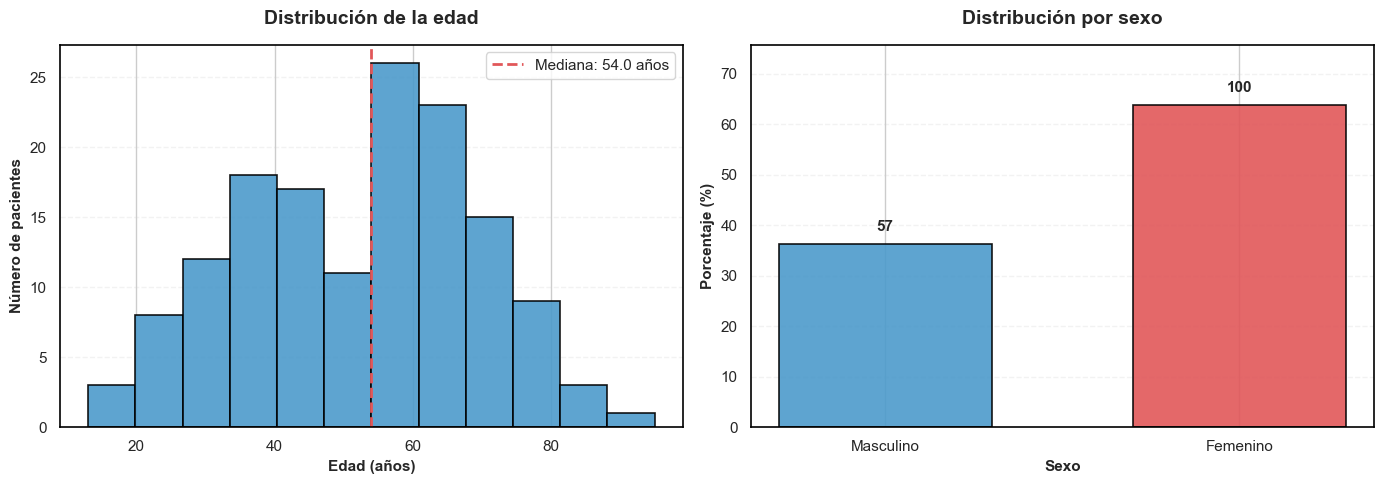

In [20]:
df_spyglass["SEXO"] = (
    df_spyglass["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_spyglass["EDAD"].dropna(),
    bins=12,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

axes[0].axvline(
    df_spyglass["EDAD"].median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {df_spyglass['EDAD'].median():.1f} años"
)

axes[0].set_title(
    "Distribución de la edad",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Edad (años)",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)
axes[0].legend()

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

sexo_counts = df_spyglass["SEXO"].value_counts()
sexo_percentages = sexo_counts / sexo_counts.sum() * 100

orden_sexo = ["MASCULINO", "FEMENINO"]
sexo_counts = sexo_counts.reindex(orden_sexo).dropna()
sexo_percentages = sexo_percentages.reindex(sexo_counts.index)

labels_sexo = [
    "Masculino" if sexo == "MASCULINO" else "Femenino"
    for sexo in sexo_counts.index
]

colors = ["#4C9ACB", "#E15759"]

bars = axes[1].bar(
    labels_sexo,
    sexo_percentages.values,
    color=colors,
    edgecolor="black",
    linewidth=1.2,
    width=0.6,
    alpha=0.9
)

for bar, count in zip(bars, sexo_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

axes[1].set_title(
    "Distribución por sexo",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Sexo",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Porcentaje (%)",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(
    0,
    max(sexo_percentages.values) + 12
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La distribución de la edad se concentra principalmente en pacientes adultos y no presenta una asimetría marcada, lo que también se refleja en la cercanía entre la media y la mediana. En cuanto al sexo, se observa una mayor proporción de mujeres: 100 de los 157 pacientes (63,7%) son de sexo femenino, frente a 57 (36,3%) de sexo masculino.

### 2.2. Procedencia de los pacientes

La procedencia permite conocer el origen geográfico de los pacientes incluidos en la cohorte. Para obtener una primera visión de esta distribución, se analiza el departamento registrado para cada paciente y posteriormente se revisan las principales ciudades o municipios de procedencia.

In [24]:
df_spyglass["DEPARTAMENTO"] = (
    df_spyglass["DEPARTAMENTO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

departamentos = (
    df_spyglass["DEPARTAMENTO"]
    .value_counts()
    .rename_axis("Departamento")
    .reset_index(name="Frecuencia")
)

departamentos["Porcentaje (%)"] = (
    departamentos["Frecuencia"] / departamentos["Frecuencia"].sum() * 100
)

styled_departamentos = departamentos.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_departamentos = styled_departamentos.set_properties(
    subset=["Departamento"],
    **{"text-align": "left"}
)

styled_departamentos = styled_departamentos.format({
    "Frecuencia": "{:.0f}",
    "Porcentaje (%)": "{:.1f}%"
})

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_departamentos.to_html()
        + "</div>"
    )
)

Departamento,Frecuencia,Porcentaje (%)
ATLANTICO,85,54.1%
GUAJIRA,40,25.5%
BOLIVAR,13,8.3%
MAGDALENA,10,6.4%
CESAR,8,5.1%
SUCRE,1,0.6%


La procedencia de los pacientes se concentra principalmente en la región Caribe. Más de la mitad de la cohorte proviene del departamento del Atlántico, seguido por La Guajira, mientras que Bolívar, Magdalena, Cesar y Sucre presentan una participación menor. Aunque la Clínica de la Costa se encuentra en Barranquilla, la presencia de pacientes procedentes de distintos departamentos muestra que la cohorte no está conformada únicamente por pacientes del Atlántico.

La procedencia de los pacientes se analiza tanto a nivel departamental como por lugar específico de origen. Esta comparación permite observar la concentración geográfica de la cohorte e identificar las principales zonas desde las cuales provienen los pacientes atendidos.

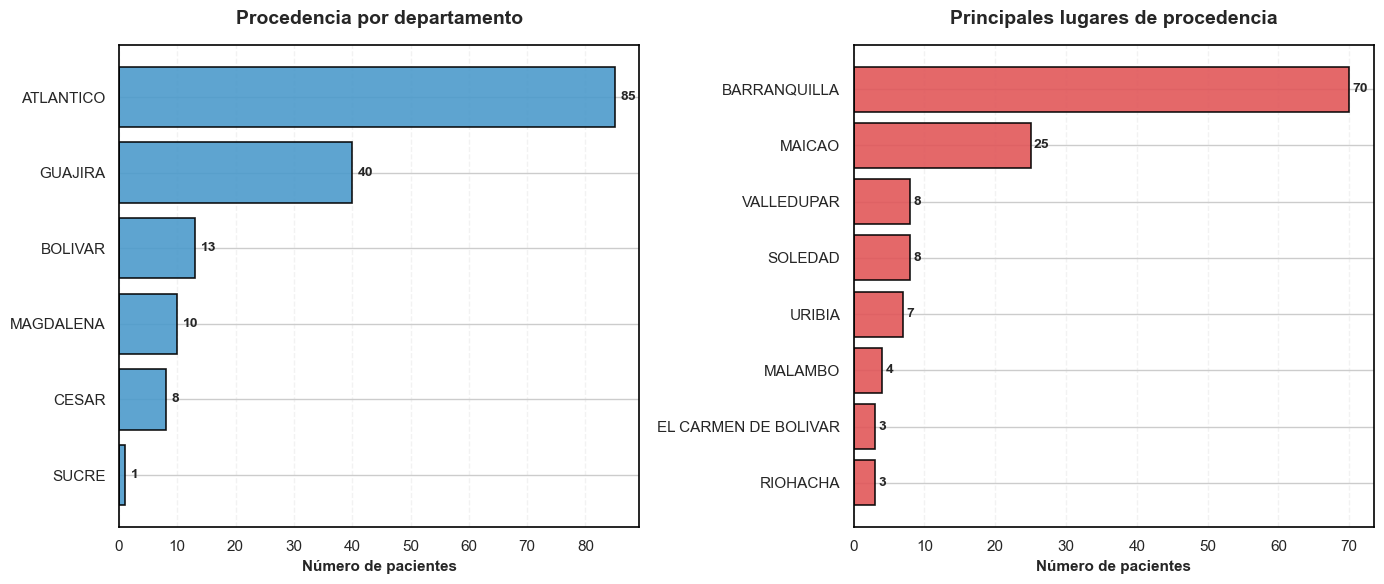

In [25]:
df_spyglass["PROCEDENCIA"] = (
    df_spyglass["PROCEDENCIA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

departamentos_plot = (
    df_spyglass["DEPARTAMENTO"]
    .value_counts()
    .sort_values(ascending=True)
)

procedencias_plot = (
    df_spyglass["PROCEDENCIA"]
    .value_counts()
    .head(8)
    .sort_values(ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bars_1 = axes[0].barh(
    departamentos_plot.index,
    departamentos_plot.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars_1, departamentos_plot.values):
    axes[0].text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title(
    "Procedencia por departamento",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel("")

axes[0].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

bars_2 = axes[1].barh(
    procedencias_plot.index,
    procedencias_plot.values,
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars_2, procedencias_plot.values):
    axes[1].text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "Principales lugares de procedencia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel("")

axes[1].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayor parte de los pacientes proviene del Atlántico, con 85 registros, seguido por La Guajira con 40. A nivel de ciudades y municipios, Barranquilla concentra 70 pacientes y Maicao 25, mientras que el resto de las procedencias presenta frecuencias considerablemente menores. En conjunto, se observa una concentración importante de pacientes provenientes del Atlántico y La Guajira, aunque la cohorte incluye registros de distintos departamentos de la región Caribe.

## 3. Contexto clínico y características del procedimiento

Después de caracterizar la cohorte, se analizan las condiciones clínicas relacionadas con la realización de SpyGlass y las principales características del procedimiento. Esta sección permite conocer los motivos por los cuales los pacientes fueron llevados a colangioscopía y describir cómo se desarrollaron los procedimientos registrados.

### 3.1. Indicaciones del procedimiento

La base de datos diferencia entre una indicación principal y una indicación secundaria para la realización de SpyGlass. Debido a que las indicaciones principales se encuentran registradas como texto libre, una misma condición clínica puede aparecer descrita de diferentes formas.

Para facilitar su análisis, se conserva el registro original y se agrupan las indicaciones en categorías clínicas generales. Estas categorías no son mutuamente excluyentes, ya que un mismo paciente puede presentar más de una condición, por lo que sus porcentajes no necesariamente suman 100%.

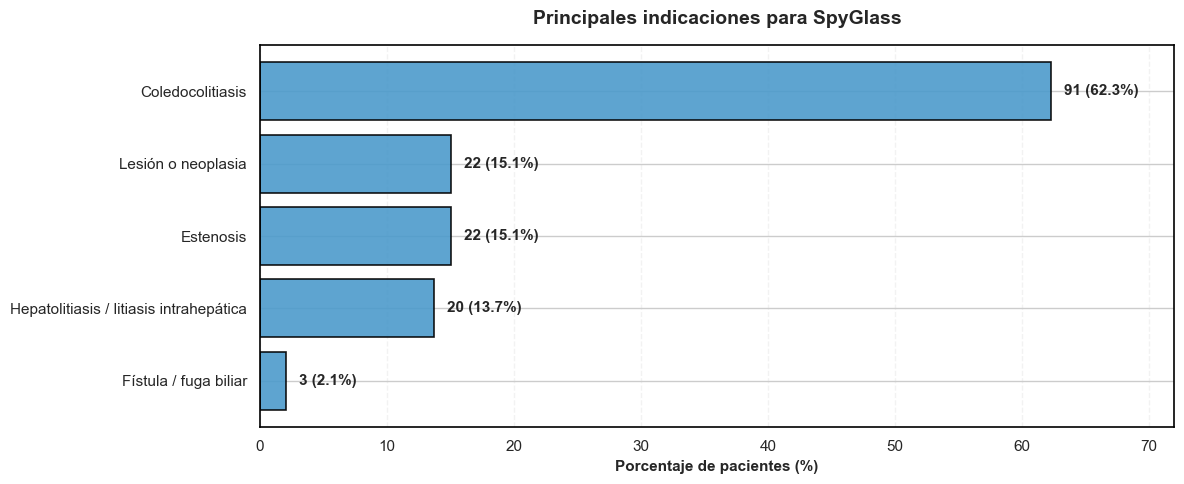

In [30]:
resumen_indicaciones_plot = resumen_indicaciones.sort_values(
    "Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.barh(
    resumen_indicaciones_plot["Indicación"],
    resumen_indicaciones_plot["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, count, percentage in zip(
    bars,
    resumen_indicaciones_plot["Pacientes"],
    resumen_indicaciones_plot["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Principales indicaciones para SpyGlass",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de pacientes (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

ax.set_xlim(0, 72)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La coledocolitiasis es la indicación predominante, presente en 91 de los 146 pacientes con información disponible (62,3%). Con una frecuencia considerablemente menor aparecen las lesiones o neoplasias y las estenosis, ambas identificadas en 22 pacientes (15,1%), seguidas por la hepatolitiasis o litiasis intrahepática en 20 (13,7%). Las fístulas o fugas biliares son poco frecuentes, con 3 casos (2,1%).

La diferencia entre la coledocolitiasis y el resto de las indicaciones muestra que las condiciones relacionadas con cálculos tienen un peso importante dentro de la cohorte. Debido a que las categorías pueden presentarse simultáneamente en un mismo paciente, estas frecuencias deben interpretarse como presencia de cada condición y no como grupos independientes.

### 3.2. Características del procedimiento

A continuación, se describen algunas características relacionadas con la realización del procedimiento, incluyendo la modalidad de atención, el número de procedimientos realizados, el tiempo quirúrgico y el uso de intervenciones complementarias como prótesis biliares o dilatación de la papila.

La mayoría de las variables relacionadas con el procedimiento presentan información para 146 pacientes, con excepción de la modalidad de atención, disponible para toda la cohorte. Para resumir estas características se analiza la modalidad en la que se realizó SpyGlass, el número de procedimientos registrados y el uso de intervenciones complementarias.

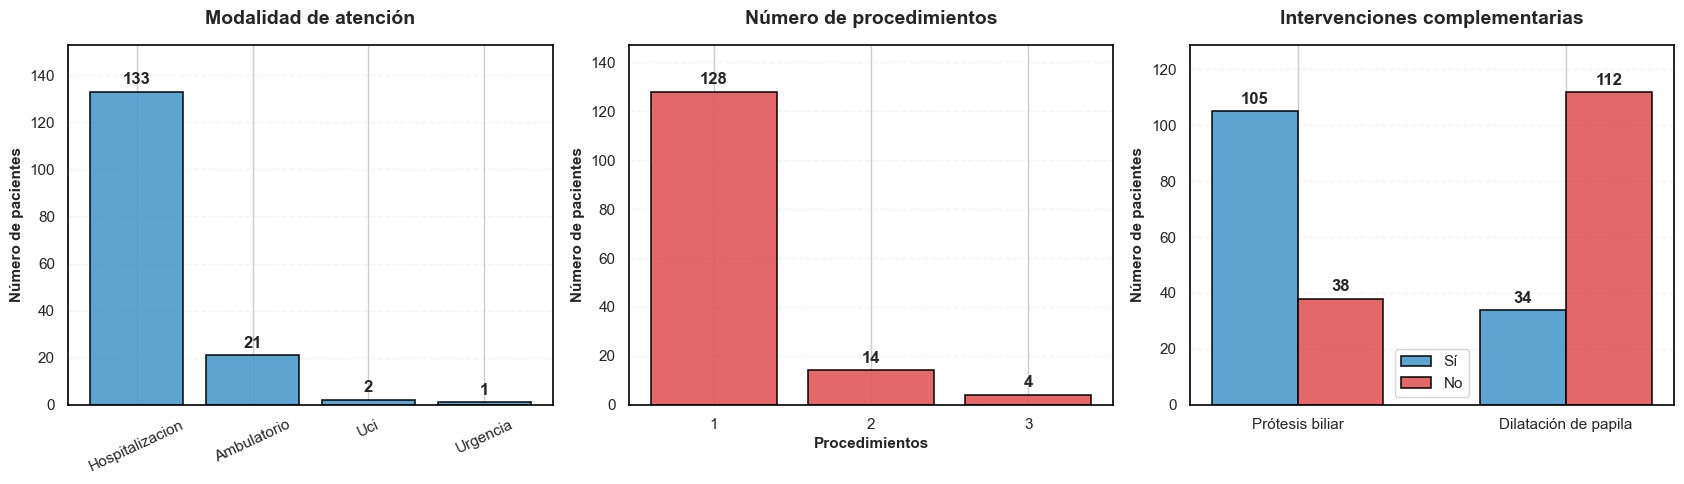

In [41]:
programado = df_spyglass["PROGRAMADO"].value_counts()

numero_procedimientos = (
    pd.to_numeric(
        df_spyglass["NUMERO DE PROCEDIMIENTOS"],
        errors="coerce"
    )
    .value_counts()
    .sort_index()
)

protesis = (
    df_spyglass["USO DE PROTESIS BILIAR"]
    .astype("string")
    .str.strip()
    .str.upper()
)

protesis = protesis.where(
    protesis.isin(["SI", "NO"]),
    "OTRO REGISTRO"
)

protesis = protesis[df_spyglass["USO DE PROTESIS BILIAR"].notna()]

dilatacion = (
    df_spyglass["DILATACION DE PAPILA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

intervenciones = pd.DataFrame({
    "Prótesis biliar": [
        (protesis == "SI").sum(),
        (protesis == "NO").sum()
    ],
    "Dilatación de papila": [
        (dilatacion == "SI").sum(),
        (dilatacion == "NO").sum()
    ]
}, index=["Sí", "No"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

bars = axes[0].bar(
    programado.index.str.title(),
    programado.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, programado.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

axes[0].set_title(
    "Modalidad de atención",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylim(0, programado.max() * 1.15)

bars = axes[1].bar(
    numero_procedimientos.index.astype(int).astype(str),
    numero_procedimientos.values,
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, numero_procedimientos.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

axes[1].set_title(
    "Número de procedimientos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Procedimientos",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(0, numero_procedimientos.max() * 1.15)

x = np.arange(len(intervenciones.columns))
width = 0.32

bars_si = axes[2].bar(
    x - width / 2,
    intervenciones.loc["Sí"],
    width,
    label="Sí",
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

bars_no = axes[2].bar(
    x + width / 2,
    intervenciones.loc["No"],
    width,
    label="No",
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

axes[2].bar_label(
    bars_si,
    padding=3,
    fontweight="bold"
)

axes[2].bar_label(
    bars_no,
    padding=3,
    fontweight="bold"
)

axes[2].set_xticks(x)
axes[2].set_xticklabels(intervenciones.columns)

axes[2].set_title(
    "Intervenciones complementarias",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[2].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[2].set_ylim(
    0,
    intervenciones.to_numpy().max() * 1.15
)

axes[2].legend()

for ax in axes:
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayoría de los procedimientos se realizó en pacientes hospitalizados, con 133 de los 157 registros, mientras que la atención ambulatoria fue considerablemente menos frecuente y los procedimientos realizados desde UCI o urgencias fueron aislados.

Entre los 146 pacientes con información disponible sobre el número de procedimientos, 128 registran un solo procedimiento, 14 registran dos y únicamente 4 registran tres. En cuanto a las intervenciones complementarias, el uso de prótesis biliar es frecuente, con 105 registros positivos frente a 38 negativos. La dilatación de papila presenta el comportamiento contrario y se registra en 34 pacientes, mientras que en 112 no se realiza.

En conjunto, la cohorte está compuesta principalmente por pacientes hospitalizados que registran un único procedimiento, con un uso frecuente de prótesis biliar y una menor utilización de dilatación de papila.

> **Nota:** Para el uso de prótesis biliar, la comparación Sí/No incluye 143 registros. Tres observaciones con descripciones diferentes a estas categorías se conservan en la base original y no se incluyen en esta comparación.

#### 3.2.1 Tiempo quirúrgico

El tiempo quirúrgico permite describir la duración de los procedimientos realizados. Para esta variable se analiza tanto su distribución como las principales medidas de tendencia central y dispersión.

In [42]:
df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"] = pd.to_numeric(
    df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"],
    errors="coerce"
)

tiempo = df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"].dropna()

resumen_tiempo = pd.DataFrame({
    "Indicador": [
        "Registros disponibles",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Mínimo",
        "Máximo"
    ],
    "Tiempo (minutos)": [
        tiempo.count(),
        tiempo.mean(),
        tiempo.std(),
        tiempo.median(),
        tiempo.min(),
        tiempo.max()
    ]
})

styled_tiempo = resumen_tiempo.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_tiempo = styled_tiempo.set_properties(
    subset=["Indicador"],
    **{"text-align": "left"}
)

styled_tiempo = styled_tiempo.format({
    "Tiempo (minutos)": "{:.1f}"
})

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_tiempo.to_html()
        + "</div>"
    )
)

Indicador,Tiempo (minutos)
Registros disponibles,146.0
Media,50.3
Desviación estándar,21.5
Mediana,50.0
Mínimo,20.0
Máximo,150.0


El tiempo quirúrgico está disponible para 146 pacientes. La duración media del procedimiento es de 50,3 minutos y la mediana de 50 minutos, con una desviación estándar de 21,5 minutos. Los tiempos registrados van desde 20 hasta 150 minutos, lo que muestra que algunos procedimientos tuvieron una duración considerablemente mayor que la habitual en la cohorte.

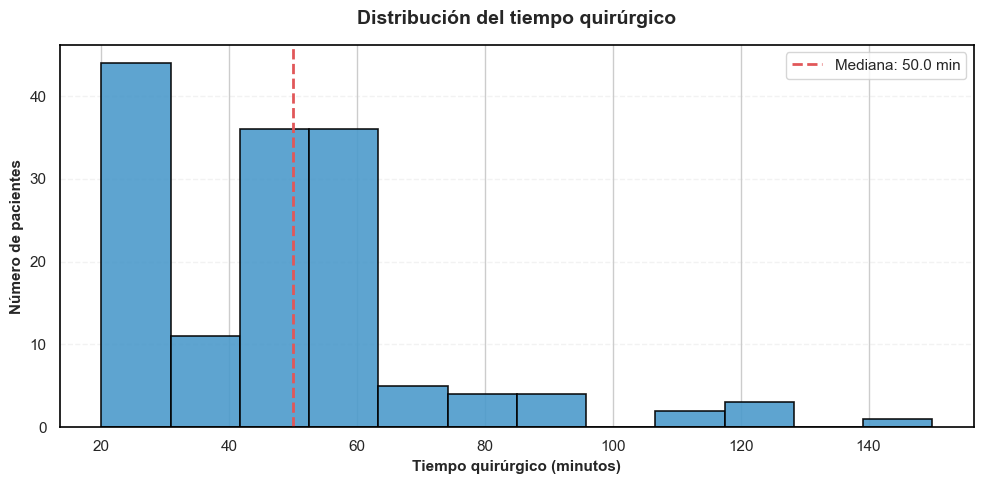

In [43]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    tiempo,
    bins=12,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

ax.axvline(
    tiempo.median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {tiempo.median():.1f} min"
)

ax.set_title(
    "Distribución del tiempo quirúrgico",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Tiempo quirúrgico (minutos)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.legend()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayor parte de los procedimientos se concentra aproximadamente entre los 20 y 60 minutos. Sin embargo, la distribución presenta una cola hacia tiempos más prolongados, con algunos procedimientos que superan los 100 minutos y un valor máximo de 150 minutos. Estos casos son poco frecuentes, pero amplían considerablemente el rango observado.

## 4. Hallazgos colangioscópicos

La visualización directa mediante SpyGlass permite registrar diferentes características de las lesiones observadas durante el procedimiento. En esta sección se describe la frecuencia de los principales hallazgos colangioscópicos disponibles en la base de datos, como paso previo al análisis de su relación con los resultados histopatológicos.

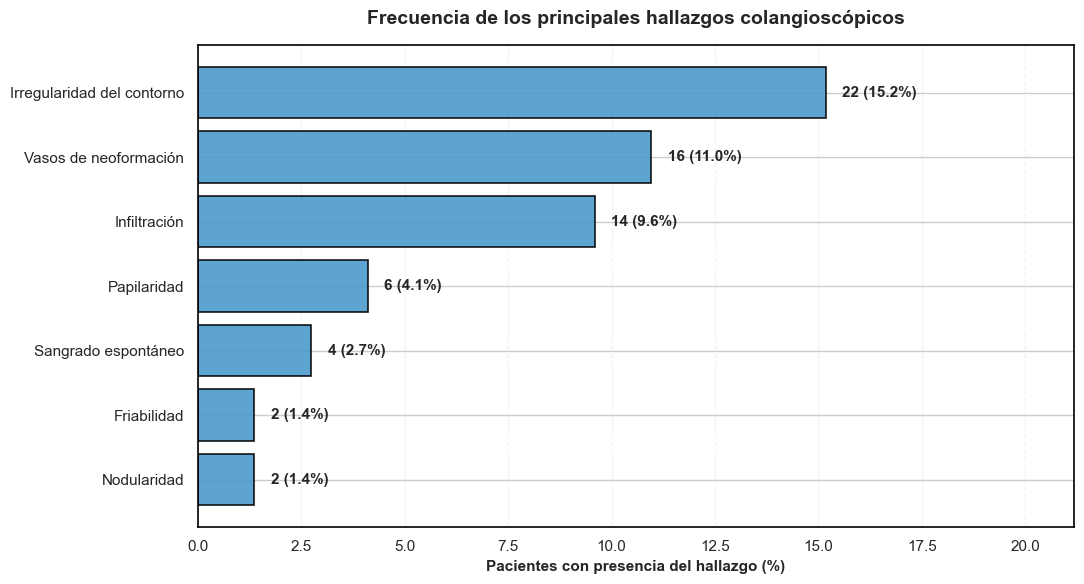

In [46]:
resumen_hallazgos = []

nombres_hallazgos = {
    "PAPILARIDAD": "Papilaridad",
    "NODULARIDAD": "Nodularidad",
    "IRREGULARIDAD DEL CONTORNO": "Irregularidad del contorno",
    "FRIABILIDAD": "Friabilidad",
    "VASOS DE NEOFORMACION": "Vasos de neoformación",
    "INFILTRACION": "Infiltración",
    "SANGRADO ESPONTANEO": "Sangrado espontáneo"
}

for variable in hallazgos:
    respuestas_validas = df_spyglass[variable].isin(["SI", "NO"])
    n_validos = respuestas_validas.sum()
    n_si = (df_spyglass.loc[respuestas_validas, variable] == "SI").sum()

    resumen_hallazgos.append({
        "Hallazgo": nombres_hallazgos[variable],
        "Pacientes": n_si,
        "Porcentaje (%)": n_si / n_validos * 100
    })

resumen_hallazgos = (
    pd.DataFrame(resumen_hallazgos)
    .sort_values("Porcentaje (%)", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    resumen_hallazgos["Hallazgo"],
    resumen_hallazgos["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, count, percentage in zip(
    bars,
    resumen_hallazgos["Pacientes"],
    resumen_hallazgos["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Frecuencia de los principales hallazgos colangioscópicos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Pacientes con presencia del hallazgo (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    resumen_hallazgos["Porcentaje (%)"].max() + 6
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La irregularidad del contorno es el hallazgo colangioscópico positivo más frecuente, presente en 22 pacientes (15,2%), seguida por los vasos de neoformación en 16 (11,0%) y la infiltración en 14 (9,6%). Los demás hallazgos presentan frecuencias menores: papilaridad se identifica en 6 pacientes (4,1%), sangrado espontáneo en 4 (2,7%), y tanto friabilidad como nodularidad en 2 pacientes (1,4%) cada una.

En general, ninguno de los hallazgos evaluados aparece en una proporción mayor al 16% de los registros con información válida. Sin embargo, su baja frecuencia no determina por sí sola su relevancia clínica, por lo que posteriormente resulta de interés evaluar si alguno de estos hallazgos se relaciona con el resultado histopatológico.

## 5. Resultados diagnósticos e histopatológicos

Además de los hallazgos observados durante la colangioscopía, la base de datos contiene información relacionada con los resultados diagnósticos obtenidos durante el estudio de los pacientes. En esta sección se explora la información disponible sobre las biopsias y su correlación con el diagnóstico anatomopatológico, con el propósito de caracterizar los desenlaces diagnósticos antes de evaluar posibles asociaciones con las características clínicas y endoscópicas.

### 5.1. Biopsias y rendimiento diagnóstico

La toma de biopsias no se realizó en todos los pacientes de la cohorte. Por esta razón, el análisis de su rendimiento se restringe al subgrupo con biopsia registrada, evitando interpretar como resultados negativos aquellos casos en los que no se realizó el procedimiento.

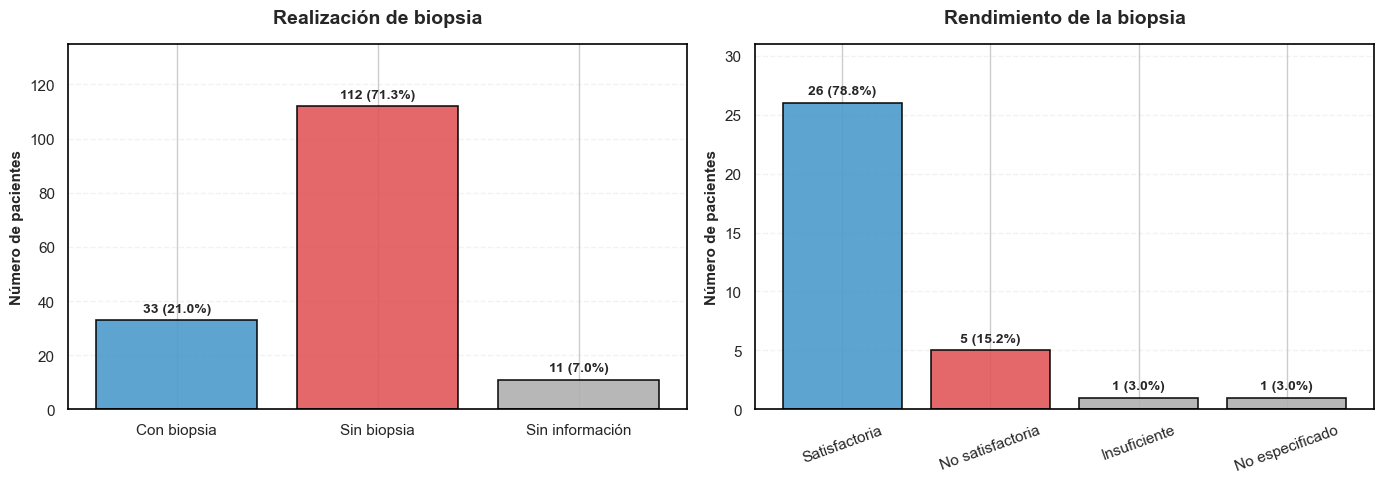

In [50]:
estado_biopsia = pd.Series({
    "Con biopsia": 33,
    "Sin biopsia": 112,
    "Sin información": 11
})

rendimiento_biopsia = pd.Series({
    "Satisfactoria": 26,
    "No satisfactoria": 5,
    "Insuficiente": 1,
    "No especificado": 1
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_biopsia = ["#4C9ACB", "#E15759", "#B0B0B0"]

bars = axes[0].bar(
    estado_biopsia.index,
    estado_biopsia.values,
    color=colors_biopsia,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, estado_biopsia.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value} ({value / 157 * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title(
    "Realización de biopsia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylim(0, 135)

colors_rendimiento = ["#4C9ACB", "#E15759", "#B0B0B0", "#B0B0B0"]

bars = axes[1].bar(
    rendimiento_biopsia.index,
    rendimiento_biopsia.values,
    color=colors_rendimiento,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, rendimiento_biopsia.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value} ({value / 33 * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "Rendimiento de la biopsia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(0, 31)
axes[1].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La biopsia se encuentra registrada en 33 pacientes (21,0% de la cohorte), mientras que en 112 (71,3%) no se realizó y en 11 (7,0%) no se dispone de información. Esto limita el análisis histopatológico a un subconjunto relativamente pequeño de los pacientes incluidos en el estudio.

Entre los 33 pacientes con biopsia, 26 muestras (78,8%) se clasifican como satisfactorias. Cinco (15,2%) se registran como no satisfactorias, una como insuficiente (3,0%) y una no cuenta con una clasificación específica (3,0%). Por lo tanto, aunque la biopsia se realizó en una proporción reducida de la cohorte, la mayoría de las muestras obtenidas dentro de este subgrupo fueron consideradas satisfactorias.